# Feature Engineering & Preprocessing Pipeline
**Goal:** a robust, leak-free, reusable scikit-learn preprocessing pipeline covering missing-value imputation, scaling, categorical encoding (One-Hot + Target), correlation analysis and feature-importance ranking.

**Dataset:** German Credit Risk (1,000 rows, 20 mixed numeric/categorical features, binary default target), loaded from OpenML `credit-g` with a GitHub-mirror fallback, and a synthetic credit dataset as a last resort so the notebook always runs.

**Key design rule:** the train/test split happens **before** any fitted transformation. Every imputer, scaler and encoder is fit on training data only, inside a `Pipeline`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Load a complex tabular dataset

In [2]:
def load_data():
    try:
        from sklearn.datasets import fetch_openml
        d = fetch_openml("credit-g", version=1, as_frame=True, parser="auto")
        X, y = d.data.copy(), (d.target == "bad").astype(int)   # 1 = default / bad credit
        return X, y, "OpenML credit-g (German Credit Risk)"
    except Exception as e:
        print("OpenML unavailable:", type(e).__name__, "-> trying GitHub mirror of German Credit")
    try:
        url = "https://raw.githubusercontent.com/selva86/datasets/master/GermanCredit.csv"
        df = pd.read_csv(url)
        y = (df.pop("credit_risk") == 0).astype(int)   # in this file 1 = good, so 1 = default is credit_risk == 0
        return df, y, "German Credit Risk (GitHub mirror, 1,000 rows)"
    except Exception as e:
        print("GitHub mirror unavailable -> using synthetic fallback:", type(e).__name__)
        rng = np.random.default_rng(RANDOM_STATE); n = 2000
        X = pd.DataFrame({
            "duration": rng.integers(4, 72, n),
            "credit_amount": np.round(rng.lognormal(7.8, 0.8, n)),
            "age": rng.integers(19, 75, n),
            "installment_commitment": rng.integers(1, 5, n),
            "existing_credits": rng.integers(1, 5, n),
            "checking_status": rng.choice(["<0", "0<=X<200", ">=200", "no checking"], n),
            "credit_history": rng.choice(["critical", "existing paid", "delayed", "all paid", "no credits"], n),
            "purpose": rng.choice([f"purpose_{i}" for i in range(10)], n),
            "employment": rng.choice(["unemployed", "<1", "1<=X<4", "4<=X<7", ">=7"], n),
            "housing": rng.choice(["own", "rent", "free"], n),
            "job": rng.choice(["unskilled", "skilled", "high qualif", "unemployed"], n),
        })
        logit = (-2.2 + 0.03*X.duration + 0.0002*X.credit_amount - 0.01*X.age
                 + 0.9*(X.checking_status == "<0") + 0.6*(X.credit_history == "critical"))
        y = pd.Series((rng.random(n) < 1/(1+np.exp(-logit))).astype(int))
        return X, y, "Synthetic credit-risk data"

X, y, source = load_data()
print("Source:", source, "| shape:", X.shape, "| default rate: %.1f%%" % (100*y.mean()))
X.head()

OpenML unavailable: URLError -> trying GitHub mirror of German Credit


Source: German Credit Risk (GitHub mirror, 1,000 rows) | shape: (1000, 20) | default rate: 30.0%


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,4,real estate,67,none,own,2,skilled employee/official,1,yes,yes
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee/official,1,no,yes
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,3,real estate,49,none,own,1,unskilled - resident,2,no,yes
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,4,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,4,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes


In [3]:
print(X.dtypes.value_counts(), "\n")
print("Missing values in raw data:", int(X.isna().sum().sum()))
display(X.describe().T)
display(X.select_dtypes(exclude="number").nunique().to_frame("n_unique").T)

str      13
int64     7
Name: count, dtype: int64 

Missing values in raw data: 0


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
present_residence,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
number_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
people_liable,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


,status,credit_history,purpose,savings,employment_duration,personal_status_sex,other_debtors,property,other_installment_plans,housing,job,telephone,foreign_worker
n_unique,4,5,10,5,5,4,3,4,3,3,4,2,2


**Simulating realistic missingness.** The raw data is complete, so to exercise the imputation step we randomly blank out ~5% of cells in a few columns (MCAR). This is done on the *whole frame before splitting* only because it is a data-generation step standing in for messy real-world data. It uses no statistics learned from the data, so it cannot leak information.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
X_raw = X.copy()
num_cols_all = X_raw.select_dtypes(include="number").columns.tolist()
cat_cols_all = X_raw.select_dtypes(exclude="number").columns.tolist()
for col in num_cols_all[:3] + cat_cols_all[:3]:
    mask = rng.random(len(X_raw)) < 0.05
    X_raw[col] = X_raw[col].astype(object).where(~mask, np.nan) if col in cat_cols_all else X_raw[col].astype(float).where(~mask, np.nan)
print("Columns with injected NaN:")
print(X_raw.isna().sum()[lambda s: s > 0])

Columns with injected NaN:
status              50
duration            53
credit_history      48
purpose             52
amount              38
installment_rate    54
dtype: int64


## 2. Train/test split **before** any transformation

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "| test:", X_test.shape)
print("default rate  train %.3f | test %.3f" % (y_train.mean(), y_test.mean()))

train: (800, 20) | test: (200, 20)
default rate  train 0.300 | test 0.300


## 3. ColumnTransformer with per-type Pipelines
| Feature group | Steps |
|---|---|
| Numeric | median impute -> `StandardScaler` |
| Low-cardinality categorical (<= 6 levels) | most-frequent impute -> `OneHotEncoder(handle_unknown="ignore")` |
| High-cardinality categorical (> 6 levels) | most-frequent impute -> `TargetEncoder` (cross-fitted internally to limit target leakage) |

Column groups are decided from the **training** set only.

In [6]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
card = X_train[cat_cols].nunique()
low_card  = card[card <= 6].index.tolist()
high_card = card[card > 6].index.tolist()
print("numeric:", num_cols); print("one-hot:", low_card); print("target-enc:", high_card)

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale",  StandardScaler())])
onehot_pipe  = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
target_pipe  = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("target", TargetEncoder(target_type="binary", smooth="auto",
                                                  cv=5, random_state=RANDOM_STATE))])

transformers = [("num", numeric_pipe, num_cols), ("ohe", onehot_pipe, low_card)]
if high_card:
    transformers.append(("tgt", target_pipe, high_card))
preprocessor = ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=True)
preprocessor.set_output(transform="pandas")
preprocessor

numeric: ['duration', 'amount', 'installment_rate', 'present_residence', 'age', 'number_credits', 'people_liable']
one-hot: ['status', 'credit_history', 'savings', 'employment_duration', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']
target-enc: ['purpose']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ohe', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [7]:
# Fit on TRAIN only, then apply to test
Xtr = preprocessor.fit_transform(X_train, y_train)
Xte = preprocessor.transform(X_test)
print("train:", Xtr.shape, "| test:", Xte.shape)
print("NaNs after preprocessing -> train:", int(Xtr.isna().sum().sum()), "| test:", int(Xte.isna().sum().sum()))
Xtr.head()

train: (800, 52) | test: (200, 52)
NaNs after preprocessing -> train: 0 | test: 0


,num__duration,num__amount,num__installment_rate,num__present_residence,num__age,num__number_credits,num__people_liable,ohe__status_... < 100 DM,ohe__status_... >= 200 DM / salary for at least 1 year,ohe__status_0 <= ... < 200 DM,...,ohe__housing_rent,ohe__job_management/self-employed/highly qualified employee/officer,ohe__job_skilled employee/official,ohe__job_unemployed/unskilled - non-resident,ohe__job_unskilled - resident,ohe__telephone_no,ohe__telephone_yes,ohe__foreign_worker_no,ohe__foreign_worker_yes,tgt__purpose
828,1.318803,2.012136,0.044710,1.053413,1.057784,-0.718745,-0.436436,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.177715
997,-0.240373,-0.902068,0.961843,1.053413,0.242449,-0.718745,-0.436436,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.239855
148,1.318803,0.865183,0.044710,-0.747293,-0.663479,1.045047,-0.436436,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.327181
735,1.318803,0.330790,0.044710,-0.747293,-0.572886,-0.718745,-0.436436,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.255020
130,2.358254,2.070954,-1.789555,-0.747293,-1.025850,-0.718745,-0.436436,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.369336


### Leakage sanity checks

In [8]:
scaler = preprocessor.named_transformers_["num"].named_steps["scale"]
imputer = preprocessor.named_transformers_["num"].named_steps["impute"]
first = num_cols[0]
print(f"Scaler mean for '{first}': {scaler.mean_[0]:.4f}")
print(f"  mean of TRAIN '{first}' (non-null after impute): {Xtr['num__'+first].mul(scaler.scale_[0]).add(scaler.mean_[0]).mean():.4f}")
print(f"  mean of FULL data '{first}': {X_raw[first].mean():.4f}  <- differs: scaler never saw test rows")
print()
print("Train numeric cols ~ mean 0 / std 1 :", np.allclose(Xtr[[c for c in Xtr if c.startswith('num__')]].mean(), 0, atol=1e-8))
print("Test numeric cols mean (NOT forced to 0):", Xte[[c for c in Xte if c.startswith('num__')]].mean().round(3).to_dict())
assert imputer.statistics_[0] == X_train[first].median(), "imputer must use train median"
print("\nOK: imputer statistics come from training data only.")

Scaler mean for 'duration': 20.7750
  mean of TRAIN 'duration' (non-null after impute): 20.7750
  mean of FULL data 'duration': 21.0475  <- differs: scaler never saw test rows

Train numeric cols ~ mean 0 / std 1 : True
Test numeric cols mean (NOT forced to 0): {'num__duration': 0.048, 'num__amount': 0.173, 'num__installment_rate': 0.127, 'num__present_residence': 0.068, 'num__age': 0.101, 'num__number_credits': -0.004, 'num__people_liable': -0.068}

OK: imputer statistics come from training data only.


## 4. Correlation analysis (training data only)

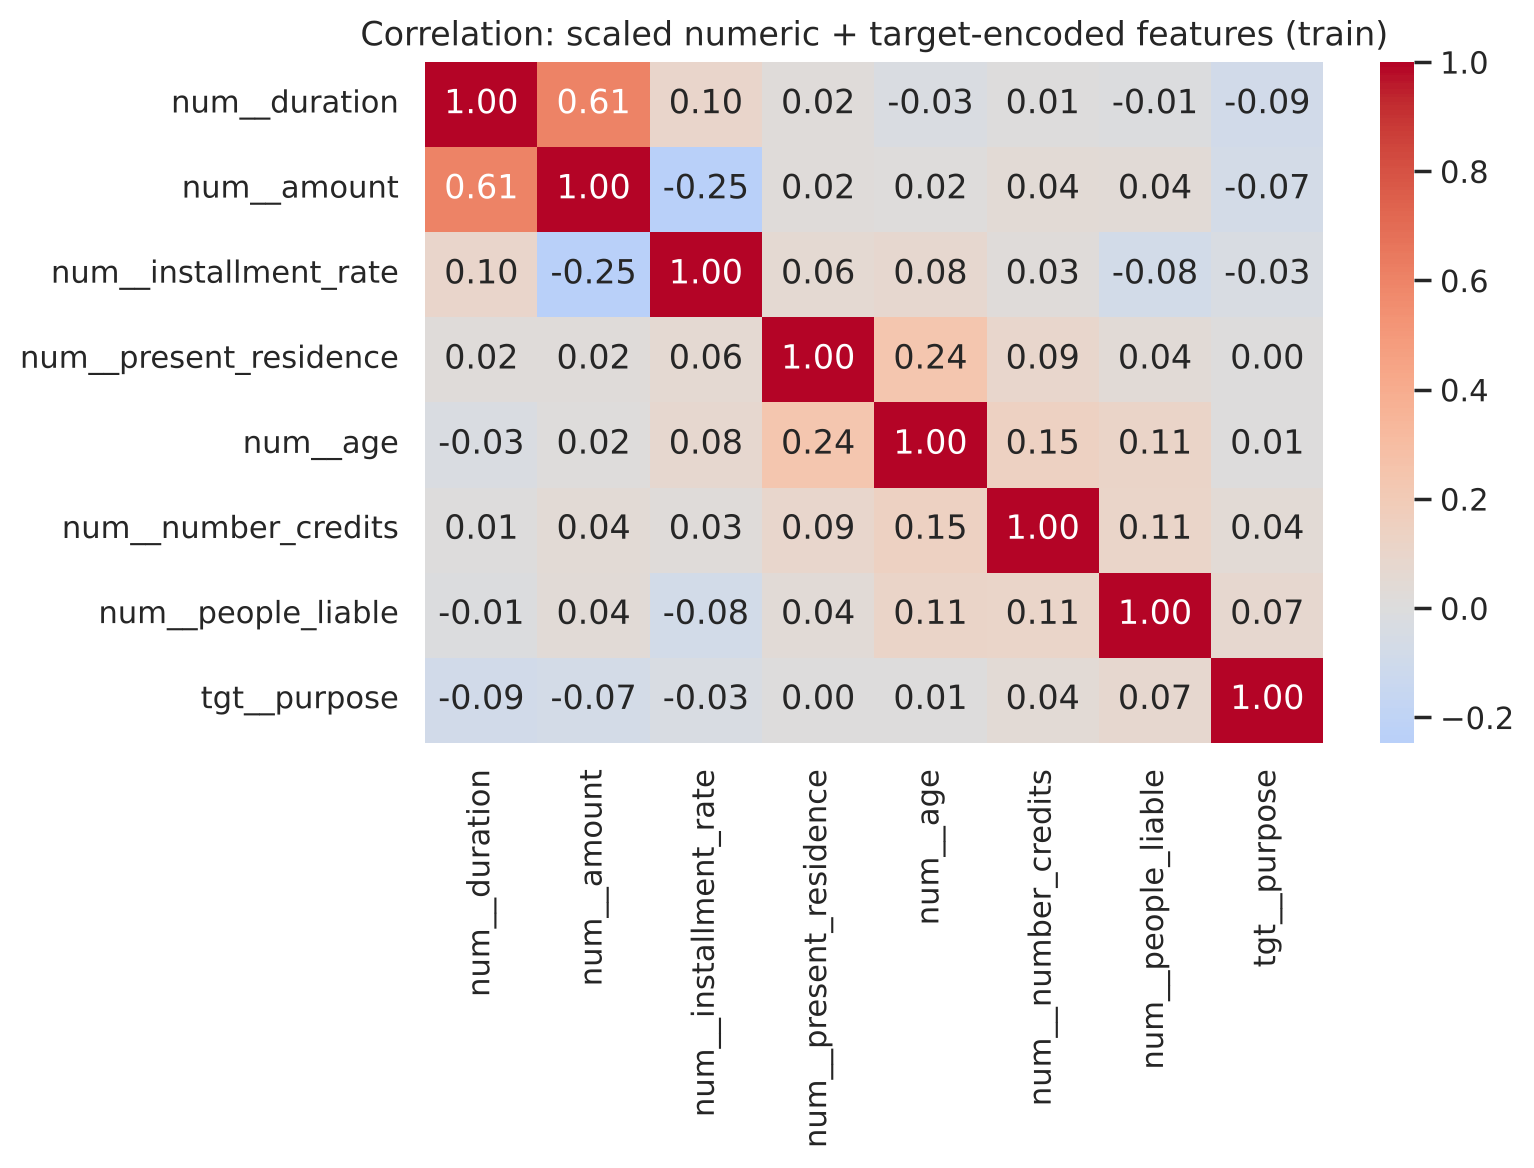

Top 10 most correlated feature pairs:


,level_0,level_1,corr
2598,ohe__foreign_worker_no,ohe__foreign_worker_yes,-1.000000
2492,ohe__telephone_no,ohe__telephone_yes,-1.000000
1962,ohe__other_installment_plans_bank,ohe__other_installment_plans_none,-0.836467
1912,ohe__property_unknown/no property,ohe__housing_for free,0.788030
2174,ohe__housing_own,ohe__housing_rent,-0.737569
1381,ohe__personal_status_sex_female : divorced/sep...,ohe__personal_status_sex_male : single,-0.724698
1644,ohe__other_debtors_guarantor,ohe__other_debtors_none,-0.705624
638,ohe__credit_history_critical account/other cre...,ohe__credit_history_existing credits paid back...,-0.688247
1592,ohe__other_debtors_co-applicant,ohe__other_debtors_none,-0.675087
2334,ohe__job_skilled employee/official,ohe__job_unskilled - resident,-0.659664


Features most correlated with default target:


,corr_with_target
ohe__status_no checking account,-0.299507
ohe__status_... < 100 DM,0.244015
num__duration,0.198710
ohe__savings_... < 100 DM,0.169395
ohe__credit_history_critical account/other credits existing,-0.168751
ohe__property_unknown/no property,0.149235
ohe__credit_history_no credits taken/all credits paid back duly,0.143577
ohe__employment_duration_... < 1 year,0.143099
ohe__housing_own,-0.138617
ohe__other_installment_plans_none,-0.137324



Pairs with |r| > 0.8: 3 (candidates for dropping to reduce multicollinearity)


In [9]:
corr = Xtr.corr()
num_only = Xtr[[c for c in Xtr if c.startswith(("num__", "tgt__"))]]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(num_only.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation: scaled numeric + target-encoded features (train)")
plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
             .rename("corr").reset_index())
pairs["abs"] = pairs["corr"].abs()
print("Top 10 most correlated feature pairs:")
display(pairs.sort_values("abs", ascending=False).head(10).drop(columns="abs"))

tgt_corr = Xtr.apply(lambda s: s.corr(y_train.reset_index(drop=True).set_axis(Xtr.index))).sort_values(key=abs, ascending=False)
print("Features most correlated with default target:")
display(tgt_corr.head(10).to_frame("corr_with_target"))
high = pairs[pairs["abs"] > 0.8]
print(f"\nPairs with |r| > 0.8: {len(high)} (candidates for dropping to reduce multicollinearity)")

## 5. Feature importance

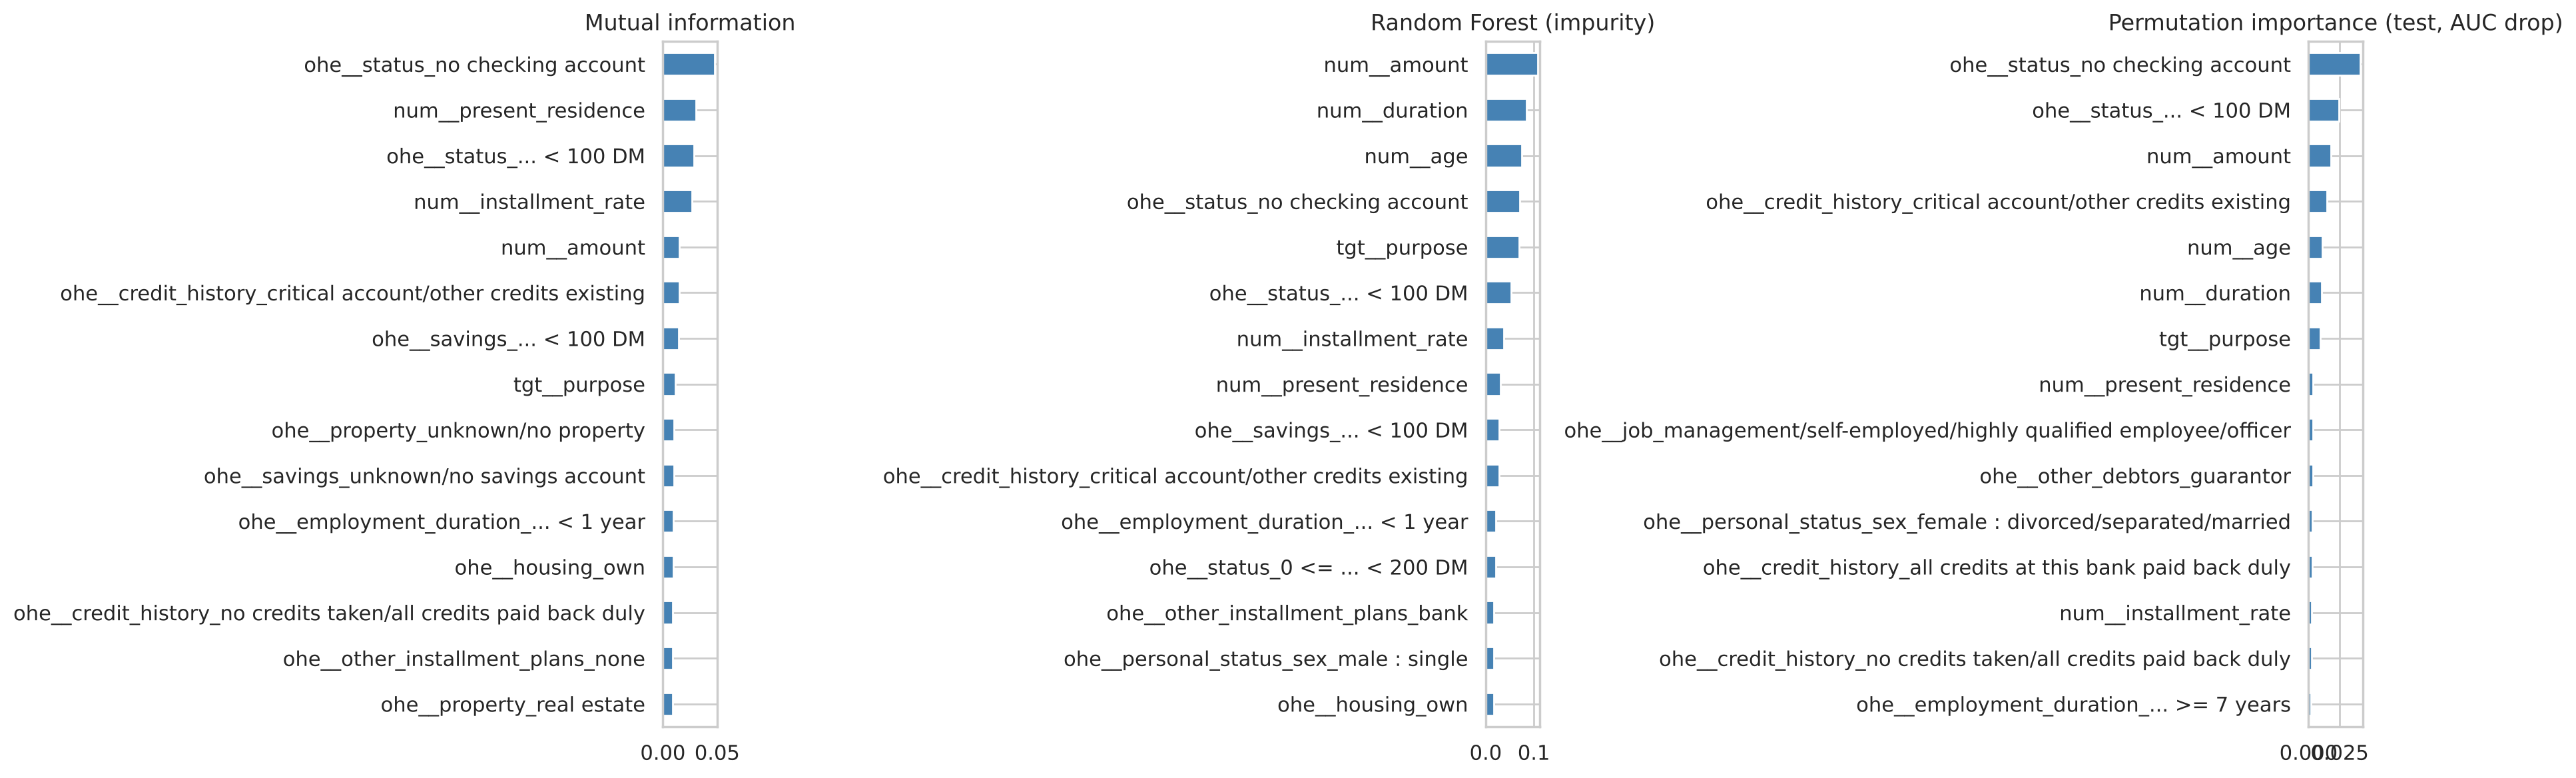

Consensus ranking (lower = more important):


,MI_rank,RF_rank,Perm_rank,mean_rank
ohe__status_no checking account,1.0,4.0,1.0,2.0
num__amount,5.0,1.0,3.0,3.0
ohe__status_... < 100 DM,3.0,6.0,2.0,3.7
num__present_residence,2.0,8.0,8.0,6.0
tgt__purpose,8.0,5.0,7.0,6.7
ohe__credit_history_critical account/other credits existing,6.0,10.0,4.0,6.7
num__installment_rate,4.0,7.0,13.0,8.0
ohe__other_installment_plans_none,14.0,18.0,16.0,16.0
ohe__property_real estate,15.0,16.0,23.0,18.0
ohe__savings_... < 100 DM,7.0,9.0,39.0,18.3


In [10]:
# (a) Mutual information (on preprocessed train features)
discrete = [c.startswith("ohe__") for c in Xtr.columns]
mi = pd.Series(mutual_info_classif(Xtr, y_train, discrete_features=discrete, random_state=RANDOM_STATE),
               index=Xtr.columns).sort_values(ascending=False)

# (b) Tree-based ranking (Random Forest on preprocessed train features)
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(Xtr, y_train)
rf_imp = pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values(ascending=False)

# (c) Permutation importance on HELD-OUT test set (more honest than impurity importance)
perm = permutation_importance(rf, Xte, y_test, scoring="roc_auc", n_repeats=15,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=Xte.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, s, t in zip(axes, [mi, rf_imp, perm_imp],
                    ["Mutual information", "Random Forest (impurity)", "Permutation importance (test, AUC drop)"]):
    s.head(15)[::-1].plot.barh(ax=ax, color="steelblue"); ax.set_title(t)
plt.tight_layout(); plt.show()

ranking = pd.concat({"MI_rank": mi.rank(ascending=False), "RF_rank": rf_imp.rank(ascending=False),
                     "Perm_rank": perm_imp.rank(ascending=False)}, axis=1)
ranking["mean_rank"] = ranking.mean(axis=1)
print("Consensus ranking (lower = more important):")
display(ranking.sort_values("mean_rank").head(15).round(1))

## 6. Reusable end-to-end pipeline (preprocessing + model) with cross-validation

In [11]:
def build_pipeline(num_cols, low_card, high_card, model=None):
    """Reusable factory: returns an unfitted preprocessing+model Pipeline."""
    tfs = [("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("scale", StandardScaler())]), num_cols),
           ("ohe", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), low_card)]
    if high_card:
        tfs.append(("tgt", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                     ("target", TargetEncoder(target_type="binary", cv=5, random_state=RANDOM_STATE))]), high_card))
    if model is None:
        model = LogisticRegression(max_iter=2000, class_weight="balanced")
    return Pipeline([("prep", ColumnTransformer(tfs)), ("model", model)])

pipe = build_pipeline(num_cols, low_card, high_card)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

# Because preprocessing lives INSIDE the pipeline, each CV fold re-fits it on that fold's training part only.
cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print("5-fold CV ROC-AUC (leak-free): %.3f +/- %.3f" % (cv_auc.mean(), cv_auc.std()))

pipe.fit(X_train, y_train)
print("Held-out test ROC-AUC:          %.3f" % roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]))

rf_pipe = build_pipeline(num_cols, low_card, high_card,
                         RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1))
rf_pipe.fit(X_train, y_train)
print("RandomForest test ROC-AUC:      %.3f" % roc_auc_score(y_test, rf_pipe.predict_proba(X_test)[:, 1]))

5-fold CV ROC-AUC (leak-free): 0.768 +/- 0.048
Held-out test ROC-AUC:          0.779


RandomForest test ROC-AUC:      0.787


In [12]:
# Persist and reload the whole pipeline - it accepts RAW dataframes (incl. NaNs and unseen categories)
joblib.dump(pipe, "credit_pipeline.joblib")
reloaded = joblib.load("credit_pipeline.joblib")
sample = X_test.head(3).copy()
sample.iloc[0, 0] = np.nan                       # missing numeric
print(reloaded.predict_proba(sample)[:, 1].round(3))

[0.203 0.356 0.828]


## Summary
- **No leakage:** split first; all imputers/scalers/encoders are fit on training data only and live inside `Pipeline`/`ColumnTransformer`, so cross-validation re-fits them per fold. Verified by explicit checks above.
- **Encoding:** One-Hot for low-cardinality, cross-fitted Target Encoding for high-cardinality categoricals.
- **Missing values:** median (numeric) / most-frequent (categorical) imputation, learned from train.
- **Analysis:** correlation heatmap + high-correlation pairs; mutual information, Random Forest and permutation importance combined into a consensus ranking.
- **Reusable:** `build_pipeline()` + a saved `credit_pipeline.joblib` that takes raw data.